## Name: Walter Roou

## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

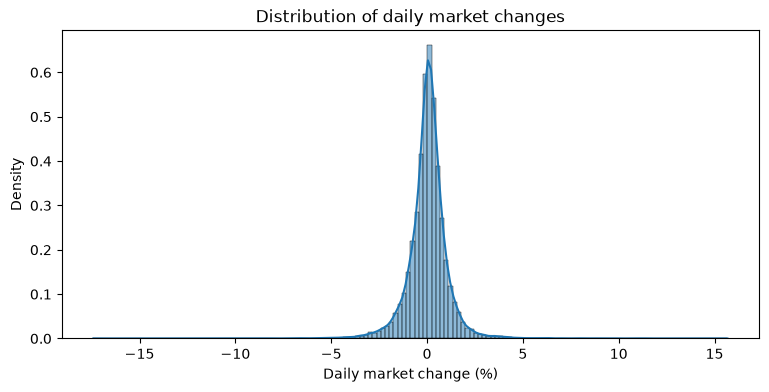

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

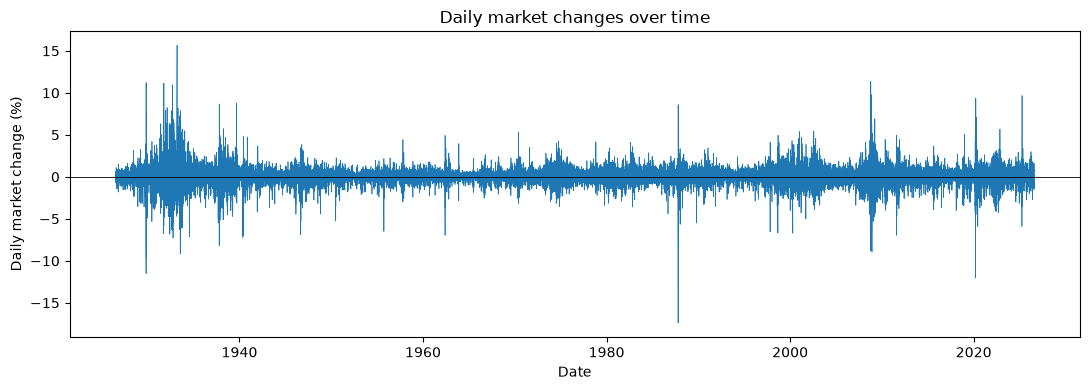

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['today'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down')
df['tomorrow'] = df['today'].shift(-1)                 # next trading day's category
df['r_next'] = df['market_return_pct'].shift(-1)       # next trading day's value
d = df.dropna(subset=['tomorrow'])                     # last day has no next day

display(pd.crosstab(d['today'], d['tomorrow'], normalize=True, margins=True).round(3))   # joint + marginals
display(pd.crosstab(d['today'], d['tomorrow'], normalize='index').round(3))             # conditional (rows sum to 1)

tomorrow,Down,Up,All
today,,,
Down,0.225,0.228,0.453
Up,0.228,0.319,0.547
All,0.453,0.547,1.000


tomorrow,Down,Up
today,,
Down,0.496,0.504
Up,0.417,0.583


Answers

- The market goes up about 55% of days and down about 45%.
- Up days are more common than down days.
- An up day is more likely after an up day (58%) than after a down day (50%).

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [5]:
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['bin'] = pd.cut(df['market_return_pct'], [-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=labels)
df['bin_next'] = df['bin'].shift(-1)

display(df['bin'].value_counts().reindex(labels))
display(pd.crosstab(df['bin'], df['bin_next'], normalize=True, margins=True).round(3))   # joint + marginals
display(pd.crosstab(df['bin'], df['bin_next'], normalize='index').round(3))             # conditional
display(df.groupby('bin', observed=True)['r_next'].describe().round(2))                 # tomorrow's value by today's bin

bin
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

bin_next,Large loss,Small loss,Near zero,Small gain,Large gain,All
bin,,,,,,
Large loss,0.021,0.027,0.009,0.028,0.020,0.105
Small loss,0.035,0.089,0.034,0.098,0.027,0.283
Near zero,0.009,0.042,0.021,0.049,0.009,0.131
Small gain,0.025,0.100,0.055,0.159,0.033,0.372
Large gain,0.014,0.026,0.012,0.038,0.020,0.109
All,0.105,0.283,0.131,0.372,0.109,1.000


bin_next,Large loss,Small loss,Near zero,Small gain,Large gain
bin,,,,,
Large loss,0.203,0.259,0.086,0.265,0.186
Small loss,0.125,0.313,0.121,0.345,0.097
Near zero,0.071,0.321,0.160,0.377,0.071
Small gain,0.067,0.269,0.148,0.428,0.088
Large gain,0.127,0.235,0.107,0.348,0.183


,count,mean,std,min,25%,50%,75%,max
bin,,,,,,,,
Large loss,2759.0,-0.04,1.72,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.04,1.01,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.02,0.83,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.11,0.83,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.16,1.38,-12.00,-0.37,0.15,0.73,15.67


Answers

- Counts: Small gain has the most days. Large loss has the fewest. Most days are small moves. (I used market_return_pct as is, even though the table says log return.)
- Joint: The most common pair is a small gain followed by another small gain (about 16%).
- Conditional: No matter what happens today, the two most likely days tomorrow are a small gain or a small loss. Only the Large loss row is close to an even .2 each. The others lean toward small gains (up to .43), but it's still hard to predict tomorrow.
- Tomorrow's returns: The average for tomorrow is close to 0, but it goes up a little from loss days (about -0.04%) to large gain days (about +0.16%).
- Spread: After a big loss (std 1.72) or a big gain (std 1.38), tomorrow swings the most, with big losses the highest. It has the widest min/max and the highest standard deviation. Big days are followed by big days, and calm days by calm days.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

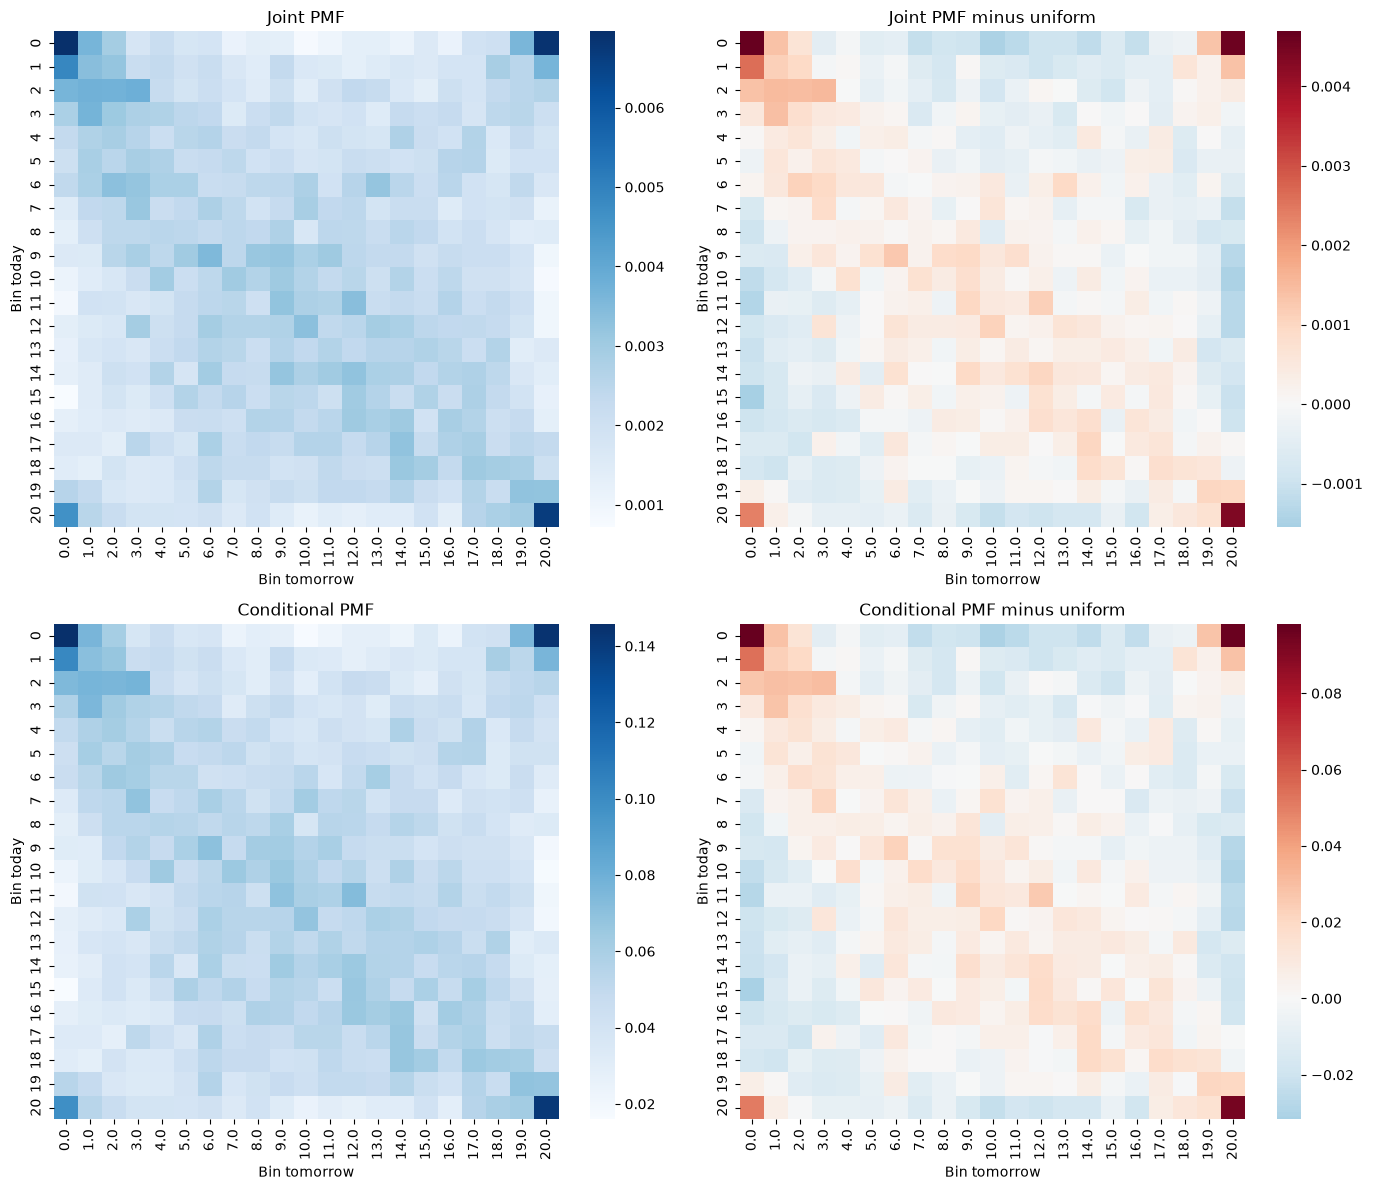

In [6]:
df['y_t'] = pd.qcut(df['market_return_pct'], 21, labels=False)   # 0 = worst days, 20 = best days
df['y_tp1'] = df['y_t'].shift(-1).astype('Int64')

joint21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
cond21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for row, (pmf, even, name) in enumerate([(joint21, 1/21**2, 'Joint'), (cond21, 1/21, 'Conditional')]):
    sns.heatmap(pmf, cmap='Blues', ax=axes[row, 0]).set(title=f'{name} PMF', xlabel='Bin tomorrow', ylabel='Bin today')
    sns.heatmap(pmf - even, cmap='RdBu_r', center=0, ax=axes[row, 1]).set(title=f'{name} PMF minus uniform', xlabel='Bin tomorrow', ylabel='Bin today')
plt.tight_layout()
plt.show()

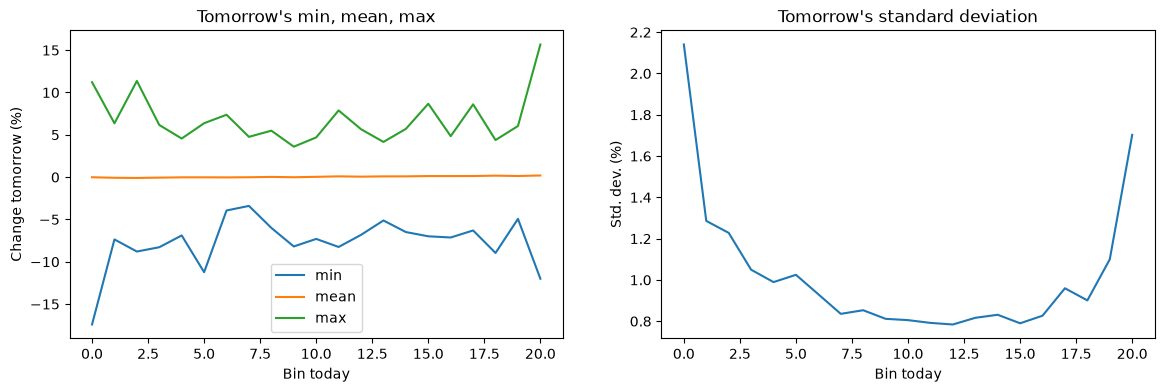

,min,mean,max,std
y_t,,,,
0,-17.41,-0.01,11.22,2.14
1,-7.36,-0.08,6.36,1.29
2,-8.79,-0.10,11.36,1.23
3,-8.28,-0.06,6.16,1.05
4,-6.89,-0.02,4.56,0.99
5,-11.23,-0.02,6.37,1.02
6,-3.94,-0.03,7.37,0.93
7,-3.40,-0.01,4.76,0.84
8,-6.00,0.03,5.49,0.85


In [7]:
nxt = df.groupby('y_t')['r_next'].agg(['min', 'mean', 'max', 'std'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
nxt[['min', 'mean', 'max']].plot(ax=axes[0], title="Tomorrow's min, mean, max", xlabel='Bin today', ylabel='Change tomorrow (%)')
nxt['std'].plot(ax=axes[1], title="Tomorrow's standard deviation", xlabel='Bin today', ylabel='Std. dev. (%)')
plt.show()
nxt.round(2)

Answers

- Joint heatmap: It looks mostly flat. After subtracting the even value, the corners stand out. Very bad or very good days tend to be followed by very bad or very good days.
- Conditional heatmap: Same idea. After an extreme day, tomorrow is more likely to be extreme too, either up or down.
- Min, mean, max: The mean is close to 0 but goes up a little from the low bins to the high bins. The min and max spread out at the ends, so tomorrow's range is wider after extreme days.
- Standard deviation: It's U-shaped with it being low in the middle and high at both ends. Wild days are followed by wild days.
- How easy is it to predict the market? Very hard. You can't really tell if tomorrow will be up or down. You can only guess that a big day will probably be followed by another big day.